<a href="https://colab.research.google.com/github/kotha-suganya/Marine-Debris-Detector/blob/main/ocean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import os

# 1. Install a clean version of the AWS tool
!pip install awscli

# 2. Define the source (NASA Marine Debris) and your local folder
# This path is the official public S3 link for the dataset
remote_path = "s3://us-west-2.opendata.source.coop/nasa/marine-debris/data/"
local_path = "./nasa_data"

# 3. Create the local folder
if not os.path.exists(local_path):
    os.makedirs(local_path)

# 4. Run the 'sync' command
# --no-sign-request means you don't need an AWS account or password
print("Starting bulk download... this will take a few minutes.")
!aws s3 sync {remote_path} {local_path} --no-sign-request

print("\nSuccess! Your data is ready in the 'nasa_data' folder.")

Starting bulk download... this will take a few minutes.

Success! Your data is ready in the 'nasa_data' folder.


In [7]:
# Check the main folders
!ls nasa_data

# See how many images and labels you have
print("Total Images:")
!ls nasa_data/image_chips | wc -l
print("Total Labels:")
!ls nasa_data/labels | wc -l

documentation.pdf  labels  README.md  source
Total Images:
ls: cannot access 'nasa_data/image_chips': No such file or directory
0
Total Labels:
1478


In [8]:
import os

# 1. Re-install AWS CLI just in case
!pip install awscli --quiet

# 2. Setup the correct paths
# Note the endpoint_url: this is the secret key to making it work!
endpoint = "https://data.source.coop"
remote_path = "s3://nasa/marine-debris/"
local_path = "nasa_data"

# 3. Start the download
print("Starting download via Source Cooperative Proxy...")
!aws s3 sync {remote_path} {local_path} --endpoint-url {endpoint} --no-sign-request

print("\n--- Check the results ---")
!ls -R nasa_data | head -n 20

Starting download via Source Cooperative Proxy...

--- Check the results ---
nasa_data:
documentation.pdf
labels
README.md
source

nasa_data/labels:
20160928_153233_0e16_16816-29821-16.geojson
20160928_153233_0e16_16816-29821-16.npy
20160928_153233_0e16_16816-29824-16.geojson
20160928_153233_0e16_16816-29824-16.npy
20160928_153233_0e16_16816-29825-16.geojson
20160928_153233_0e16_16816-29825-16.npy
20160928_153233_0e16_16816-29828-16.geojson
20160928_153233_0e16_16816-29828-16.npy
20160928_153233_0e16_16816-29829-16.geojson
20160928_153233_0e16_16816-29829-16.npy
20160928_153233_0e16_16816-29830-16.geojson
20160928_153233_0e16_16816-29830-16.npy
20160928_153233_0e16_16816-29831-16.geojson


In [9]:
import numpy as np
import os
import shutil

# 1. Setup paths
source_labels = 'nasa_data/labels/'
source_images = 'nasa_data/source/'
yolo_base = 'yolo_dataset/'
os.makedirs(yolo_base + 'labels/train', exist_ok=True)
os.makedirs(yolo_base + 'images/train', exist_ok=True)

# 2. Function to convert NASA box [xmin, ymin, xmax, ymax] to YOLO [x_center, y_center, w, h]
def convert_to_yolo_format(size, box):
    dw = 1. / size[0]
    dh = 1. / size[1]
    x = (box[0] + box[2]) / 2.0
    y = (box[1] + box[3]) / 2.0
    w = box[2] - box[0]
    h = box[3] - box[1]
    return (x * dw, y * dh, w * dw, h * dh)

# 3. Processing loop
count = 0
for file in os.listdir(source_labels):
    if file.endswith('.npy'):
        # Load the NASA label data
        data = np.load(os.path.join(source_labels, file))

        # Create matching .txt file
        txt_filename = file.replace('.npy', '.txt')
        with open(os.path.join(yolo_base + 'labels/train', txt_filename), 'w') as f:
            # NASA npy files contain an array of bounding boxes
            for box in data:
                # box format usually [xmin, ymin, xmax, ymax]
                yolo_box = convert_to_yolo_format((256, 256), box)
                # '0' is the class ID for 'Marine Debris'
                f.write(f"0 {yolo_box[0]} {yolo_box[1]} {yolo_box[2]} {yolo_box[3]}\n")

        # Copy the matching JPG image to our new folder
        img_filename = file.replace('.npy', '.jpg')
        if os.path.exists(os.path.join(source_images, img_filename)):
            shutil.copy(os.path.join(source_images, img_filename), os.path.join(yolo_base + 'images/train', img_filename))
            count += 1

print(f"Success! Processed {count} images and labels into /yolo_dataset")

Success! Processed 739 images and labels into /yolo_dataset


In [10]:
import sys
!{sys.executable} -m pip install ultralytics

from ultralytics import YOLO
import os

# 2. Re-create the data.yaml just to be safe
yaml_content = """
path: /content/yolo_dataset
train: images/train
val: images/train

names:
  0: Marine_Debris
"""

with open('data.yaml', 'w') as f:
    f.write(yaml_content)

# 3. Start Training
# Load the model
model = YOLO('yolov8n.pt')

# Train
# device='cpu' tells it to use the CPU
# Changing device to 0 tells YOLO to use the available GPU
model.train(data='data.yaml', epochs=50, imgsz=256, device=0)

Ultralytics 8.4.90 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a42d03017c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 


image 1/1 /content/img.jpg: 160x256 2 Marine_Debriss, 10.0ms
Speed: 0.8ms preprocess, 10.0ms inference, 1.6ms postprocess per image at shape (1, 3, 160, 256)
------------------------------
RESULT: SUCCESS! 2 Debris cluster(s) detected.
------------------------------


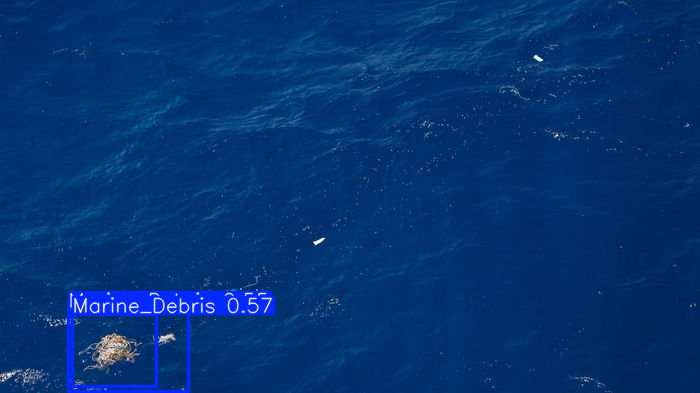

In [24]:
from ultralytics import YOLO
import cv2
import os
from google.colab.patches import cv2_imshow

# 1. Load your custom trained model
model = YOLO('/content/runs/detect/train/weights/best.pt')

# 2. Path to the image you want to check
# You can change this to any image you upload to Colab
image_path = 'img.jpg'

# 3. Run prediction
# conf=0.25 means the AI must be 25% sure it's debris to report it
results = model.predict(source=image_path, conf=0.25, save=False)

# 4. Logic to say "Debris Found" or "Not"
for result in results:
    # Get the number of boxes found
    num_objects = len(result.boxes)

    print("-" * 30)
    if num_objects > 0:
        print(f"RESULT: SUCCESS! {num_objects} Debris cluster(s) detected.")
    else:
        print("RESULT: No Debris detected in this image.")
    print("-" * 30)

    # 5. Optional: Show the image so you can verify
    im_array = result.plot()
    cv2_imshow(im_array)

In [25]:
# Folder path
test_folder = 'yolo_dataset/images/train/'

# Get all images in that folder
images = [f for f in os.listdir(test_folder) if f.endswith('.jpg')]

print(f"{'Image Name':<40} | {'Status':<15}")
print("-" * 60)

for img_name in images[:10]: # Testing first 10
    img_path = os.path.join(test_folder, img_name)
    results = model.predict(source=img_path, conf=0.25, verbose=False)

    status = "DEBRIS FOUND" if len(results[0].boxes) > 0 else "CLEAN"
    print(f"{img_name:<40} | {status:<15}")

Image Name                               | Status         
------------------------------------------------------------
20170927_154610_0e14_16738-29841-16.jpg  | DEBRIS FOUND   
20181024_160202_0f3b_16790-29819-16.jpg  | CLEAN          
20170326_153233_0e26_17064-29742-16.jpg  | DEBRIS FOUND   
20161008_153105_0e3a_16930-29808-16.jpg  | DEBRIS FOUND   
20161008_153104_0e3a_16817-29826-16.jpg  | CLEAN          
20170322_153132_0e0f_17136-29798-16.jpg  | CLEAN          
20160928_153233_0e16_16816-29828-16.jpg  | CLEAN          
20170322_153132_0e0f_17118-29799-16.jpg  | DEBRIS FOUND   
20170323_152750_0e20_17303-29801-16.jpg  | DEBRIS FOUND   
20181023_155747_0f34_16709-29829-16.jpg  | DEBRIS FOUND   
